# Track 1: Smart Campus Energy Prediction

Predict `energy_usage` for a campus building from the building, the time, the weather, occupancy and the previous reading.
Main metric is RMSE, also reported: MAE and R².

**Outline**
1. Load data
2. EDA
3. Preprocessing
4. Validation setup
5. Baselines and models
6. Final model and tuning
7. Error analysis
8. Insights for the campus
9. Train on all data, predict test, save files

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from pathlib import Path

from sklearn.model_selection import KFold, train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

SEED = 42
N_JOBS = 4  # shared machine, don't use every core

# Folder with the two csv files. On Colab, upload them next to the notebook.
DATA_DIR = Path("../Track 1 Dataset")
if not DATA_DIR.exists():
    DATA_DIR = Path(".")

plt.rcParams["figure.dpi"] = 100

## 1. Load data

In [2]:
train = pd.read_csv(DATA_DIR / "Track 1 Training Dataset.csv")
test = pd.read_csv(DATA_DIR / "Track 1 Testing Dataset.csv")
TARGET = "energy_usage"

print("train:", train.shape, " test:", test.shape)
print("columns only in train:", set(train.columns) - set(test.columns))
train.head()

train: (8000, 11)  test: (3000, 10)
columns only in train: {'energy_usage'}


,id,building_id,building_type,hour,day_of_week,month,temperature,humidity,occupancy,previous_usage,energy_usage
0,EC000685,LEC_A,LectureHall,2,Monday,9,25.2,81.9,31.0,28.0,27.2
1,EC003261,SCI_A,Science,1,Wednesday,11,25.7,83.7,14.0,72.6,67.2
2,EC005451,RES_A,Residential,5,Sunday,1,26.3,84.7,199.0,51.6,54.2
3,EC000188,ENG_A,Engineering,21,Wednesday,5,29.1,77.4,68.0,68.3,63.6
4,EC001001,SPT_A,Sports,16,Wednesday,5,30.9,68.2,65.0,49.1,53.9


In [3]:
train.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
hour,8000.0,11.49,6.91,0.0,6.0,11.0,17.0,23.0
month,8000.0,6.54,3.44,1.0,4.0,7.0,10.0,12.0
temperature,7881.0,28.22,1.88,23.2,26.8,28.2,29.6,35.8
humidity,7881.0,78.05,5.57,61.1,74.3,78.0,81.7,100.0
occupancy,7878.0,72.58,74.33,0.0,8.0,42.0,129.0,337.0
previous_usage,7886.0,49.67,18.94,5.3,35.9,46.4,61.4,149.4
energy_usage,8000.0,51.25,18.45,13.2,38.0,48.1,62.7,143.9


In [4]:
# missing values: test has a lot more than train
missing = pd.DataFrame({
    "train_%": train.isna().mean() * 100,
    "test_%": test.isna().mean() * 100,
}).round(1)
missing[missing.sum(axis=1) > 0]

,train_%,test_%
humidity,1.5,6.1
occupancy,1.5,6.9
previous_usage,1.4,6.8
temperature,1.5,7.0


In [5]:
print("duplicate ids:", train["id"].duplicated().sum())
print("duplicate rows (ignoring id):", train.drop(columns="id").duplicated().sum())
print("buildings:", train["building_id"].nunique(), "| building types:", train["building_type"].nunique())
print("each building has one type:", (train.groupby("building_id")["building_type"].nunique() == 1).all())
print("target skew:", round(train[TARGET].skew(), 3))

duplicate ids: 0
duplicate rows (ignoring id): 0
buildings: 12 | building types: 8
each building has one type: True
target skew: 0.723


**Notes**
- 8000 train rows, 3000 test rows, 12 buildings across 8 building types.
- No date or year column, only hour, day of week and month, so we can't split by time. The rows are a random sample, so random K-fold is the right validation.
- Skew is about 0.7, which is below 1, so we don't log-transform the target.
- **Test has ~7% missing values per column versus ~1.5% in train.** This matters because `previous_usage` is the strongest predictor (see below). We come back to this in section 4.

## 2. EDA

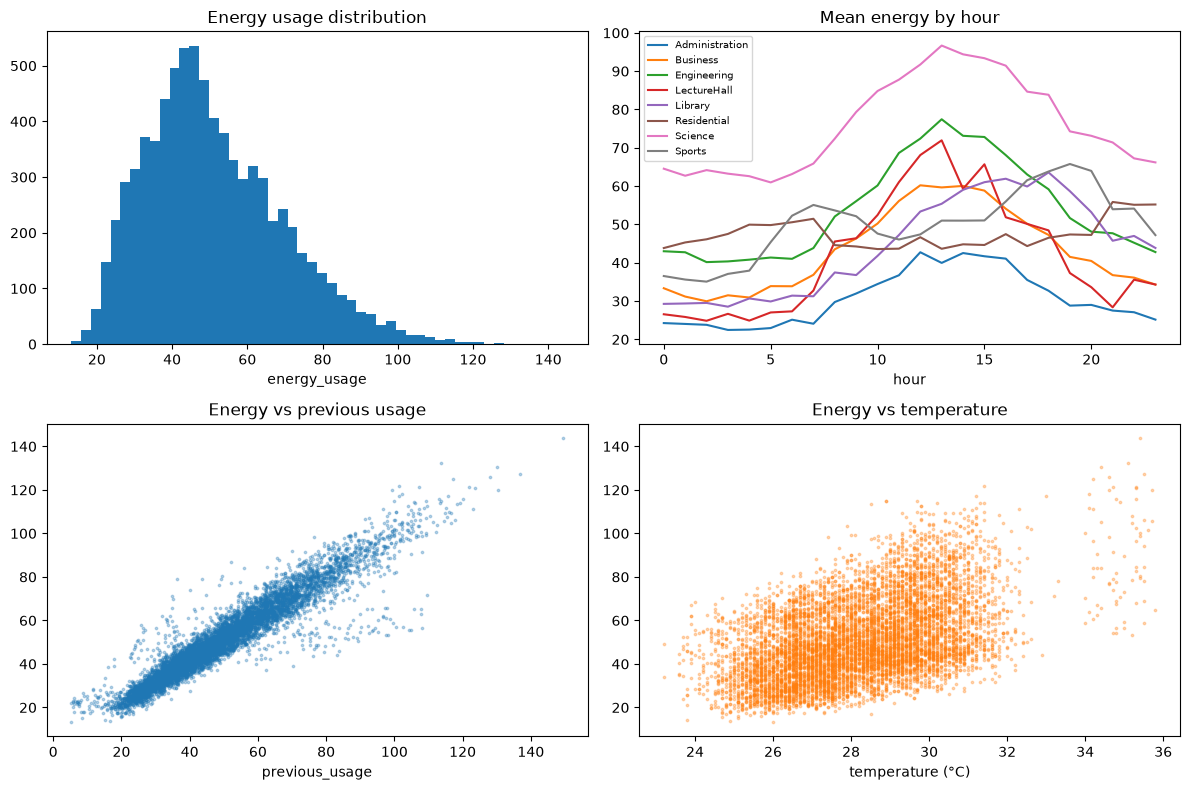

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0, 0].hist(train[TARGET], bins=50, color="tab:blue")
axes[0, 0].set_title("Energy usage distribution")
axes[0, 0].set_xlabel("energy_usage")

for btype, grp in train.groupby("building_type"):
    axes[0, 1].plot(grp.groupby("hour")[TARGET].mean(), label=btype)
axes[0, 1].set_title("Mean energy by hour")
axes[0, 1].set_xlabel("hour")
axes[0, 1].legend(fontsize=7)

axes[1, 0].scatter(train["previous_usage"], train[TARGET], s=3, alpha=0.3)
axes[1, 0].set_title("Energy vs previous usage")
axes[1, 0].set_xlabel("previous_usage")

axes[1, 1].scatter(train["temperature"], train[TARGET], s=3, alpha=0.3, color="tab:orange")
axes[1, 1].set_title("Energy vs temperature")
axes[1, 1].set_xlabel("temperature (°C)")

plt.tight_layout()
plt.show()

In [7]:
num_cols = ["hour", "month", "temperature", "humidity", "occupancy", "previous_usage"]
train[num_cols + [TARGET]].corr()[TARGET].drop(TARGET).sort_values(ascending=False).round(3)

previous_usage    0.945
temperature       0.489
occupancy         0.412
hour              0.236
month            -0.065
humidity         -0.250
Name: energy_usage, dtype: float64

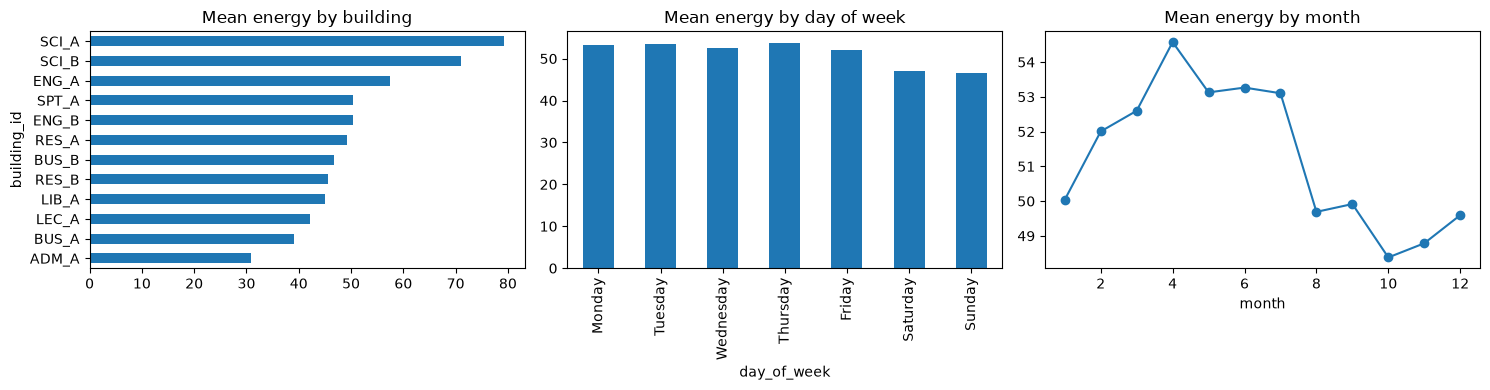

In [8]:
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
train.groupby("building_id")[TARGET].mean().sort_values().plot.barh(ax=axes[0])
axes[0].set_title("Mean energy by building")
train.groupby("day_of_week")[TARGET].mean().reindex(day_order).plot.bar(ax=axes[1])
axes[1].set_title("Mean energy by day of week")
train.groupby("month")[TARGET].mean().plot(marker="o", ax=axes[2])
axes[2].set_title("Mean energy by month")
plt.tight_layout()
plt.show()

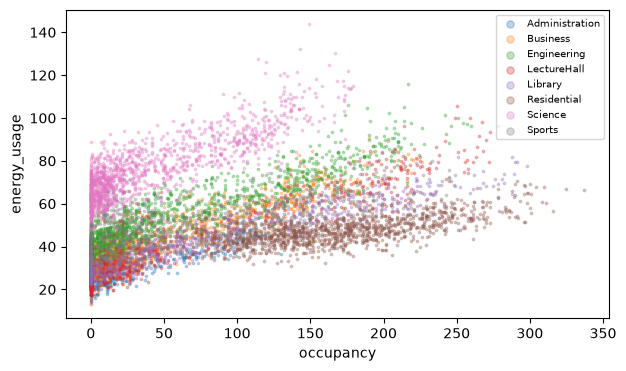

In [9]:
# occupancy vs energy for each building type
fig, ax = plt.subplots(figsize=(7, 4))
for btype, grp in train.groupby("building_type"):
    ax.scatter(grp["occupancy"], grp[TARGET], s=3, alpha=0.3, label=btype)
ax.set_xlabel("occupancy")
ax.set_ylabel("energy_usage")
ax.legend(fontsize=7, markerscale=3)
plt.show()

**EDA findings**
- `previous_usage` is by far the strongest predictor (r ≈ 0.95), so energy is very persistent from one reading to the next.
- Temperature (r ≈ 0.49) and occupancy (r ≈ 0.41) come next. Hotter means more cooling load.
- Usage has a clear daytime peak for most building types, and the shape differs by type (e.g. residential vs lecture hall). This interaction is why a tree model should beat a linear one.
- Buildings have quite different base loads (Science/Engineering high, Admin/Business low).
- Day of week and month show little effect on their own.
- No duplicates, no impossible values, no zero or negative targets.

## 3. Preprocessing

Everything lives inside a sklearn `Pipeline`, so `model.pkl` runs on the raw test csv.

- **Tree models:** categoricals ordinal-encoded and passed as native categoricals. `HistGradientBoosting` handles NaN by itself, so no imputation, and the model learns what a missing value means.
- **Ridge baseline:** one-hot encode categoricals plus hour and month (so it can learn the daily shape), and impute numeric NaN with the median.

We didn't add sin/cos or interaction features: trees split on hour directly and find interactions (e.g. building type × hour) themselves.

In [10]:
CAT_COLS = ["building_id", "building_type", "day_of_week"]
NUM_COLS = ["hour", "month", "temperature", "humidity", "occupancy", "previous_usage"]
FEATURES = CAT_COLS + NUM_COLS

X = train[FEATURES]
y = train[TARGET]


def make_ridge():
    prep = ColumnTransformer([
        ("onehot", OneHotEncoder(handle_unknown="ignore"), CAT_COLS + ["hour", "month"]),
        ("num", SimpleImputer(strategy="median"), ["temperature", "humidity", "occupancy", "previous_usage"]),
    ])
    return make_pipeline(prep, Ridge(alpha=1.0))


def make_forest():
    prep = ColumnTransformer([
        ("onehot", OneHotEncoder(handle_unknown="ignore"), CAT_COLS),
        ("num", SimpleImputer(strategy="median"), NUM_COLS),
    ])
    return make_pipeline(prep, RandomForestRegressor(n_estimators=300, min_samples_leaf=3,
                                                     n_jobs=N_JOBS, random_state=SEED))


def make_hgb(learning_rate=0.1, max_leaf_nodes=31, max_iter=100):
    prep = ColumnTransformer([
        ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), CAT_COLS),
        ("num", "passthrough", NUM_COLS),
    ])
    model = HistGradientBoostingRegressor(
        categorical_features=[0, 1, 2],  # first 3 columns out of the ColumnTransformer
        learning_rate=learning_rate,
        max_leaf_nodes=max_leaf_nodes,
        max_iter=max_iter,
        random_state=SEED,
    )
    return make_pipeline(prep, model)

## 4. Validation setup

5-fold shuffled K-fold. Since test has much more missing data than train, we score every model twice:
- **clean**: the validation fold as it is
- **test-like**: the validation fold with extra values blanked out, so each column's missing rate matches the test set

The test-like score is the one closer to the leaderboard.

We also try **missing-value augmentation**: add a copy of the training fold with random values blanked out, so the model sees enough rows with missing `previous_usage` to learn what to do then. This happens inside each fold, so the validation rows never leak into training.

In [11]:
kf = KFold(n_splits=5, shuffle=True, random_state=SEED)

# extra missing rate needed so validation looks like the test set
extra_missing = (test[NUM_COLS].isna().mean() - train[NUM_COLS].isna().mean()).clip(lower=0)
print(extra_missing.round(3))


def add_missing(df, rates, seed):
    """Blank out values at random, with a given rate per column."""
    df = df.copy()
    rng = np.random.default_rng(seed)
    for col, rate in rates.items():
        df.loc[rng.random(len(df)) < rate, col] = np.nan
    return df


X_testlike = add_missing(X, extra_missing, seed=SEED)


def scores(y_true, y_pred):
    return {
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAE": mean_absolute_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
    }


def run_cv(make_model, augment_rate=0.0):
    """Returns out-of-fold predictions on clean and on test-like validation data."""
    oof_clean = np.zeros(len(X))
    oof_testlike = np.zeros(len(X))
    for fold, (tr_idx, va_idx) in enumerate(kf.split(X)):
        X_tr, y_tr = X.iloc[tr_idx], y.iloc[tr_idx]
        if augment_rate > 0:
            rates = {col: augment_rate for col in ["temperature", "humidity", "occupancy", "previous_usage"]}
            X_tr = pd.concat([X_tr, add_missing(X_tr, rates, seed=fold)])
            y_tr = pd.concat([y_tr, y_tr])
        model = make_model().fit(X_tr, y_tr)
        oof_clean[va_idx] = model.predict(X.iloc[va_idx])
        oof_testlike[va_idx] = model.predict(X_testlike.iloc[va_idx])
    return oof_clean, oof_testlike

hour              0.000
month             0.000
temperature       0.055
humidity          0.046
occupancy         0.053
previous_usage    0.053
dtype: float64


## 5. Baselines and models

In [12]:
results = []


def record(name, oof_clean, oof_testlike):
    row = {"model": name, **scores(y, oof_clean), "RMSE test-like": scores(y, oof_testlike)["RMSE"]}
    results.append(row)
    return row


# baseline 1: mean energy of the same building at the same hour
oof_gm = np.zeros(len(X))
for tr_idx, va_idx in kf.split(X):
    means = train.iloc[tr_idx].groupby(["building_id", "hour"])[TARGET].mean()
    keys = pd.MultiIndex.from_frame(X.iloc[va_idx][["building_id", "hour"]])
    oof_gm[va_idx] = means.reindex(keys).fillna(y.iloc[tr_idx].mean()).values
record("Mean per (building, hour)", oof_gm, oof_gm)

# baseline 2: just predict the previous reading (only rows where it exists)
has_prev = X["previous_usage"].notna()
naive = scores(y[has_prev], X.loc[has_prev, "previous_usage"])
print("previous_usage as prediction:", {k: round(v, 3) for k, v in naive.items()})

record("Ridge (linear)", *run_cv(make_ridge))
record("Random forest", *run_cv(make_forest))
record("HistGradientBoosting", *run_cv(make_hgb))
record("HistGradientBoosting + missing aug (10%)", *run_cv(make_hgb, augment_rate=0.10))

pd.DataFrame(results).set_index("model").round(3)

previous_usage as prediction: {'RMSE': np.float64(6.401), 'MAE': 4.316, 'R2': 0.88}


,RMSE,MAE,R2,RMSE test-like
model,,,,
"Mean per (building, hour)",7.923,5.713,0.816,7.923
Ridge (linear),3.849,2.927,0.956,4.729
Random forest,3.983,3.031,0.953,4.552
HistGradientBoosting,3.529,2.750,0.963,3.945
HistGradientBoosting + missing aug (10%),3.535,2.752,0.963,3.758


**Comparing models.** Every real model beats the group-mean baseline by a lot, because it uses `previous_usage`. Gradient boosting is best on clean data. Ridge is not far behind, so most of the relationship is close to linear. Random forest is slightly worse than Ridge.

On test-like data every model gets worse, but the augmented one degrades the least. Below we check what augmentation rate works best.

In [13]:
aug_rows = []
for rate in [0.0, 0.05, 0.10, 0.20]:
    oof_c, oof_t = run_cv(make_hgb, augment_rate=rate)
    aug_rows.append({"augment_rate": rate,
                     "RMSE clean": scores(y, oof_c)["RMSE"],
                     "RMSE test-like": scores(y, oof_t)["RMSE"]})
pd.DataFrame(aug_rows).round(3)

,augment_rate,RMSE clean,RMSE test-like
0,0.00,3.529,3.945
1,0.05,3.521,3.813
2,0.10,3.535,3.758
3,0.20,3.562,3.738


## 6. Final model and light tuning

Small grid on the two settings that matter most for boosting. We use augmentation at 10%, and pick on test-like RMSE.
We kept the grid small on purpose: with 8000 rows, a big search would mostly fit noise in the CV score.

In [14]:
AUG_RATE = 0.10

grid = [
    {"learning_rate": 0.1, "max_leaf_nodes": 31, "max_iter": 100},
    {"learning_rate": 0.05, "max_leaf_nodes": 31, "max_iter": 250},
    {"learning_rate": 0.05, "max_leaf_nodes": 15, "max_iter": 300},
    {"learning_rate": 0.03, "max_leaf_nodes": 15, "max_iter": 500},
]
tune_rows = []
for params in grid:
    oof_c, oof_t = run_cv(lambda: make_hgb(**params), augment_rate=AUG_RATE)
    tune_rows.append({**params, "RMSE clean": scores(y, oof_c)["RMSE"], "RMSE test-like": scores(y, oof_t)["RMSE"]})

tune_df = pd.DataFrame(tune_rows)
display(tune_df.round(3))

best_params = grid[int(tune_df["RMSE test-like"].idxmin())]
print("best params:", best_params)

,learning_rate,max_leaf_nodes,max_iter,RMSE clean,RMSE test-like
0,0.10,31,100,3.535,3.758
1,0.05,31,250,3.498,3.711
2,0.05,15,300,3.515,3.740
3,0.03,15,500,3.508,3.723


best params: {'learning_rate': 0.05, 'max_leaf_nodes': 31, 'max_iter': 250}


In [15]:
oof_best, oof_best_testlike = run_cv(lambda: make_hgb(**best_params), augment_rate=AUG_RATE)
record("Final: tuned HGB + missing aug", oof_best, oof_best_testlike)

results_df = pd.DataFrame(results).set_index("model").round(3)
results_df

,RMSE,MAE,R2,RMSE test-like
model,,,,
"Mean per (building, hour)",7.923,5.713,0.816,7.923
Ridge (linear),3.849,2.927,0.956,4.729
Random forest,3.983,3.031,0.953,4.552
HistGradientBoosting,3.529,2.750,0.963,3.945
HistGradientBoosting + missing aug (10%),3.535,2.752,0.963,3.758
Final: tuned HGB + missing aug,3.498,2.718,0.964,3.711


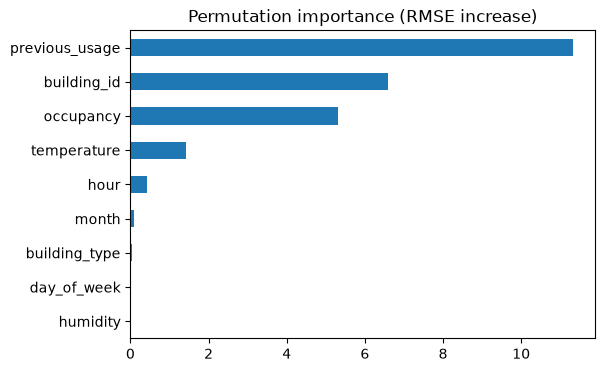

In [16]:
# which features matter (permutation importance on a held-out 20%)
X_a, X_b, y_a, y_b = train_test_split(X, y, test_size=0.2, random_state=SEED)
imp_model = make_hgb(**best_params).fit(X_a, y_a)
imp = permutation_importance(imp_model, X_b, y_b, scoring="neg_root_mean_squared_error",
                             n_repeats=5, random_state=SEED, n_jobs=1)
importance = pd.Series(imp.importances_mean, index=FEATURES).sort_values()

importance.plot.barh(figsize=(6, 4), title="Permutation importance (RMSE increase)")
plt.show()

## 7. Error analysis

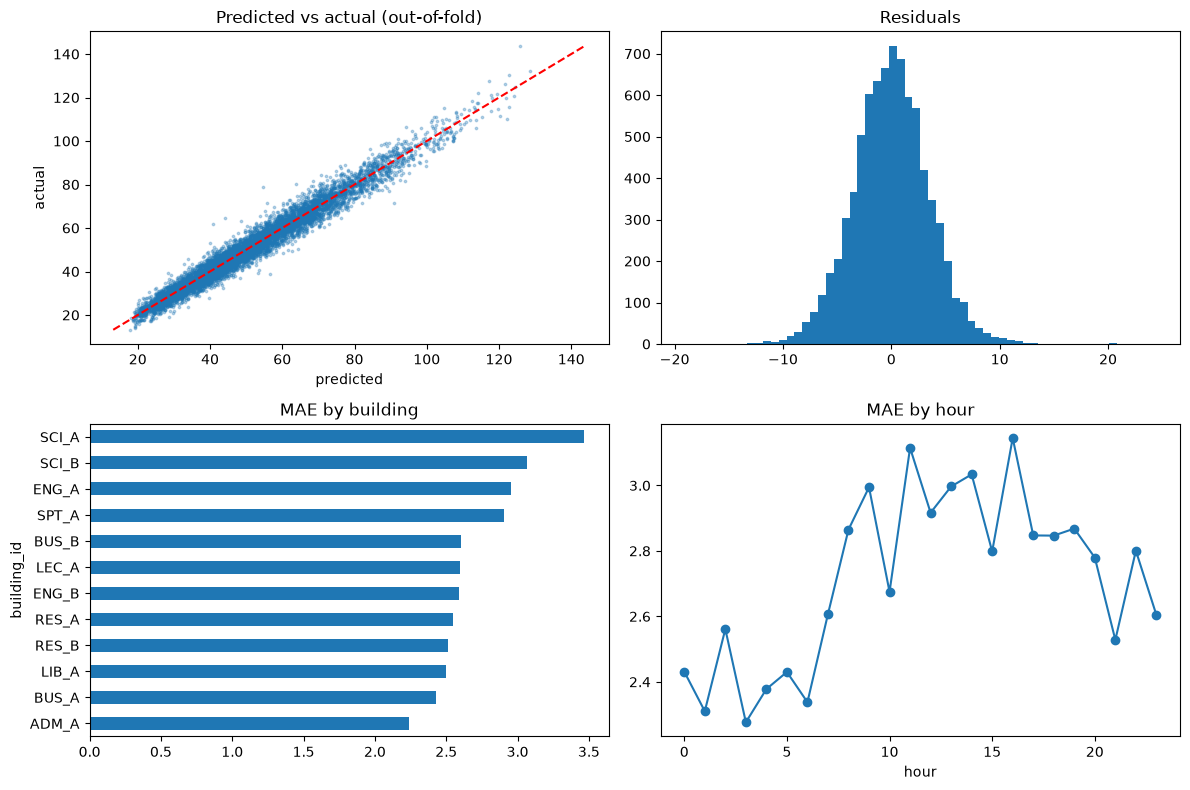

In [17]:
err = train[FEATURES + [TARGET]].copy()
err["pred"] = oof_best
err["resid"] = err[TARGET] - err["pred"]
err["abs_err"] = err["resid"].abs()

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0, 0].scatter(err["pred"], err[TARGET], s=3, alpha=0.3)
lims = [err[TARGET].min(), err[TARGET].max()]
axes[0, 0].plot(lims, lims, "r--")
axes[0, 0].set_title("Predicted vs actual (out-of-fold)")
axes[0, 0].set_xlabel("predicted")
axes[0, 0].set_ylabel("actual")

axes[0, 1].hist(err["resid"], bins=60)
axes[0, 1].set_title("Residuals")

err.groupby("building_id")["abs_err"].mean().sort_values().plot.barh(ax=axes[1, 0])
axes[1, 0].set_title("MAE by building")

err.groupby("hour")["abs_err"].mean().plot(marker="o", ax=axes[1, 1])
axes[1, 1].set_title("MAE by hour")

plt.tight_layout()
plt.show()

In [18]:
# error by month, and error when the strongest feature is missing
by_month = err.groupby("month")["abs_err"].mean().round(2)
print("MAE by month:")
print(by_month.to_string())

testlike = train[[TARGET]].copy()
testlike["pred"] = oof_best_testlike
testlike["prev_missing"] = X_testlike["previous_usage"].isna()
testlike["abs_err"] = (testlike[TARGET] - testlike["pred"]).abs()
print()
print("MAE on test-like data, by whether previous_usage is missing:")
print(testlike.groupby("prev_missing")["abs_err"].agg(["mean", "count"]).round(2))

MAE by month:
month
1     2.73
2     2.64
3     2.77
4     2.85
5     2.77
6     2.76
7     2.77
8     2.77
9     2.68
10    2.56
11    2.59
12    2.74

MAE on test-like data, by whether previous_usage is missing:
              mean  count
prev_missing             
False         2.76   7470
True          4.13    530


In [19]:
# rows with the largest errors
err.sort_values("abs_err", ascending=False).head(10).round(1)

,building_id,building_type,day_of_week,hour,month,temperature,humidity,occupancy,previous_usage,energy_usage,pred,resid,abs_err
650,SCI_A,Science,Monday,9,1,28.2,73.5,144.0,36.3,79.0,54.5,24.5,24.5
6623,SPT_A,Sports,Saturday,22,1,26.5,78.1,17.0,NaN,61.7,40.9,20.8,20.8
7027,BUS_B,Business,Friday,7,6,27.6,84.8,NaN,41.5,64.5,44.1,20.4,20.4
3753,SCI_A,Science,Thursday,9,11,26.9,73.8,152.0,44.7,71.7,90.8,-19.1,19.1
3919,SCI_A,Science,Thursday,14,3,35.4,88.4,149.0,149.4,143.9,125.8,18.1,18.1
4477,LEC_A,LectureHall,Sunday,22,6,28.5,81.6,9.0,70.2,38.9,56.6,-17.7,17.7
4722,SCI_A,Science,Wednesday,8,10,26.7,75.8,NaN,49.5,80.4,63.9,16.5,16.5
7550,LEC_A,LectureHall,Thursday,9,9,28.6,74.5,243.0,34.7,71.3,55.8,15.5,15.5
2891,SPT_A,Sports,Saturday,22,8,28.0,81.1,45.0,NaN,63.4,48.5,14.9,14.9
3010,ENG_A,Engineering,Wednesday,7,12,27.6,75.3,NaN,46.2,39.2,53.3,-14.1,14.1


In [20]:
# do errors grow with the size of the reading?
err["usage_band"] = pd.qcut(err[TARGET], 5)
err.groupby("usage_band", observed=True).agg(MAE=("abs_err", "mean"), mean_resid=("resid", "mean")).round(2)

,MAE,mean_resid
usage_band,,
"(13.199, 35.2]",2.25,-0.74
"(35.2, 44.2]",2.38,-0.47
"(44.2, 53.2]",2.62,0.14
"(53.2, 66.3]",2.86,0.22
"(66.3, 143.9]",3.49,0.87


**Error analysis findings**
- Residuals are centred on zero and roughly symmetric, so there's no systematic bias overall.
- The biggest errors come from **sudden jumps**: rows where `energy_usage` is far from `previous_usage`. The model trusts the previous reading, so a spike is predicted late. That's a limit of having only one lag, and more history would help.
- Error grows with usage level. The Science buildings have the largest MAE (SCI_A 3.5 vs ADM_A 2.2). The top usage band is under-predicted on average and the bottom band over-predicted, so the model pulls toward the mean a little.
- **Missing `previous_usage` is the single biggest risk.** On test-like data, MAE is about 50% higher on those rows (4.1 vs 2.8), even with augmentation. ~7% of test rows are like this.
- Error is fairly flat across months (2.6–2.9) and hours (2.3–3.1), so the model has captured the daily pattern.
- Several of the worst rows have a missing `previous_usage` or `occupancy`, which again points at data gaps.

## 8. Insights for the campus

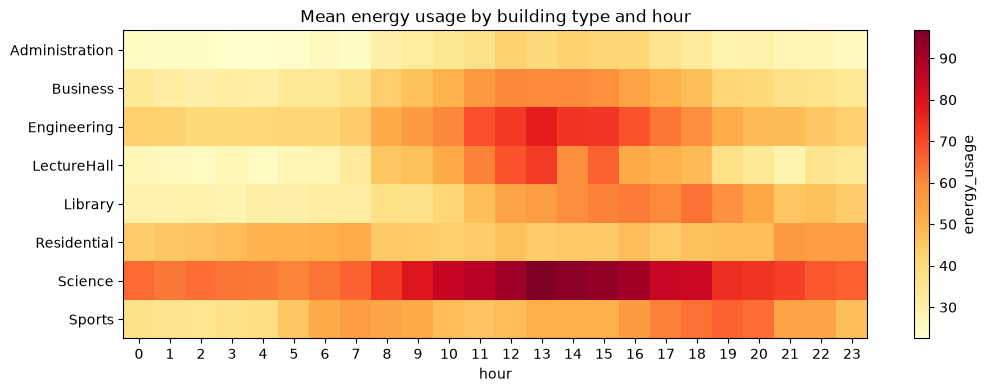

,peak_hour
building_type,
Administration,12
Business,12
Engineering,13
LectureHall,13
Library,18
Residential,21
Science,13
Sports,19


In [21]:
# typical daily profile per building type, from the actual data
profile = train.pivot_table(index="building_type", columns="hour", values=TARGET, aggfunc="mean")

fig, ax = plt.subplots(figsize=(12, 4))
im = ax.imshow(profile, aspect="auto", cmap="YlOrRd")
ax.set_yticks(range(len(profile)))
ax.set_yticklabels(profile.index)
ax.set_xticks(range(24))
ax.set_xlabel("hour")
ax.set_title("Mean energy usage by building type and hour")
plt.colorbar(im, ax=ax, label="energy_usage")
plt.show()

peak_hour = profile.idxmax(axis=1).rename("peak_hour")
peak_hour.to_frame()

In [22]:
# energy used when the building is empty: possible waste
empty = train[train["occupancy"] == 0]
waste = pd.DataFrame({
    "mean_energy_empty": empty.groupby("building_id")[TARGET].mean(),
    "mean_energy_all": train.groupby("building_id")[TARGET].mean(),
    "empty_readings": empty.groupby("building_id").size(),
})
waste["empty_vs_avg_%"] = 100 * waste["mean_energy_empty"] / waste["mean_energy_all"]
waste.sort_values("empty_vs_avg_%", ascending=False).round(1)

,mean_energy_empty,mean_energy_all,empty_readings,empty_vs_avg_%
building_id,,,,
SCI_B,60.3,71.0,133.0,84.9
SCI_A,66.3,79.2,118.0,83.7
ADM_A,24.3,30.8,114.0,78.9
SPT_A,38.6,50.5,46.0,76.6
ENG_B,38.5,50.4,100.0,76.3
BUS_B,35.4,46.7,155.0,75.8
BUS_A,29.7,39.2,163.0,75.7
ENG_A,41.6,57.4,136.0,72.5
LIB_A,29.4,45.1,98.0,65.2


**What the campus could do**
- **Off-hours waste:** the two Science buildings still use ~85% of their average load when nobody is inside (Admin ~79%). Lecture hall and library drop much more when empty (~60–65%). Science is the first place to audit equipment and HVAC schedules. Residential is never at zero occupancy, so it can't be judged this way.
- **Peak shifting:** Admin, Business, Engineering, Lecture halls and Science all peak at 12–13h. Library (18h), Sports (19h) and Residential (21h) peak in the evening. Staggering flexible loads (e.g. pre-cooling the teaching buildings before noon) would flatten the campus-wide midday peak.
- **What drives usage:** after the previous reading, the building itself and its occupancy matter most, and the weather comes after that. So occupancy-based HVAC control is likely to save more than weather-based control.
- **Sensors:** missing `previous_usage` costs the most accuracy, so fixing meter data gaps is a cheap way to improve the forecast.

## 9. Train on all data, predict test, save files

In [23]:
X_full = pd.concat([X, add_missing(X, {c: AUG_RATE for c in ["temperature", "humidity", "occupancy", "previous_usage"]}, seed=SEED)])
y_full = pd.concat([y, y])

final_model = make_hgb(**best_params).fit(X_full, y_full)

test_pred = final_model.predict(test[FEATURES]).clip(min=0)
submission = pd.DataFrame({"id": test["id"], TARGET: test_pred.round(3)})
submission.to_csv("submission.csv", index=False)

joblib.dump(final_model, "model.pkl")

print(submission.shape)
submission.head()

(3000, 2)


,id,energy_usage
0,EC010541,71.938
1,EC009755,65.913
2,EC008886,56.416
3,EC009317,65.780
4,EC008958,22.215


In [24]:
# sanity checks: model.pkl reloads and gives the same predictions on the raw test csv
reloaded = joblib.load("model.pkl")
raw_test = pd.read_csv(DATA_DIR / "Track 1 Testing Dataset.csv")
assert np.allclose(reloaded.predict(raw_test).clip(min=0).round(3), submission[TARGET])
assert len(submission) == len(test) and submission["id"].is_unique
assert submission[TARGET].notna().all()
print("all checks passed")
print(submission[TARGET].describe().round(2))

all checks passed
count    3000.00
mean       54.61
std        20.18
min        17.12
25%        40.33
50%        52.91
75%        67.09
max       127.85
Name: energy_usage, dtype: float64


## Summary

| | |
|---|---|
| Model | HistGradientBoosting (sklearn) with native categoricals and NaN handling |
| Key idea | Train with randomly blanked values so the model copes with test's 7% missing data |
| Validation | 5-fold shuffled K-fold (no timestamps, so a random split is right), scored on clean and on test-like folds |
| Files | `submission.csv`, `model.pkl` (full pipeline, runs on the raw csv), `requirements.txt` |

**Limitations:** only one lag is available, so sudden jumps are predicted late. There's no year or date column, so holidays and semester weeks can't be added. Very high readings are slightly under-predicted.